# 02 - Spectrogram Array Verification & HDF5 Inspection

**Course:** CS 351 - Artificial Intelligence  
**Project:** Classifying LIGO Glitches: Comparing CNNs and Simple Features  
**Group:** L4 Group 23 (Ismail Nooruddin, Munir Tariq, Ramsha Arshad)  

---
### Objective of this Notebook:
In this notebook, we address the instructor's explicit instruction: **"verify which measurements the spectrogram arrays support, while keeping all views of each glitch within the same data split"**.

Specifically, we:
1. Connect to the 3 GB HDF5 file (`trainingsetv1d1.h5`) and inspect its internal hierarchy.
2. Verify matrix dimensions ($140 \times 170$), data types (`float32`), and value normalization.
3. Visualize the four time zoom windows (**0.5s, 1.0s, 2.0s, 4.0s**) side-by-side for representative glitch classes.
4. Mathematically test which interpretable features (frequency peaks, active duration, spectral centroids, sub-band energies) can be computed directly from the 2D arrays.
5. Test our PyTorch `LIGOGlitchDataset` loader with batching via `DataLoader`.

In [1]:
# Step 2.1: Import necessary libraries
# os and sys are used for file paths and importing our custom src module.
# h5py is used to read the Hierarchical Data Format (.h5) array file.
# numpy and pandas handle numerical matrices and tabular data.
# matplotlib is used to render 2D spectrogram heatmaps.
# torch is used to test our PyTorch Dataset integration.
import os
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# Add project root to sys.path so we can import our src modules
sys.path.append(os.path.abspath('..'))
from src.data.dataset import load_spectrogram, load_all_views, LIGOGlitchDataset

# Configure clean inline plot display
%matplotlib inline
plt.style.use('seaborn-v0_8-white' if 'seaborn-v0_8-white' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print('All libraries and src modules imported successfully!')

All libraries and src modules imported successfully!


### Cell 1 Explanation: Setup & Custom Modules
- In the cell above, we imported `h5py` for reading the 3 GB HDF5 file and PyTorch (`torch`) for neural network dataset handling.
- We also imported our modular `load_spectrogram`, `load_all_views`, and `LIGOGlitchDataset` classes from `src/data/dataset.py`.

In [2]:
# Step 2.2: Inspect the HDF5 File Hierarchy
h5_file_path = os.path.join('..', 'trainingsetv1d1.h5')

print(f'HDF5 File Exists: {os.path.exists(h5_file_path)}')
print(f'HDF5 File Size: {os.path.getsize(h5_file_path) / (1024**3):.2f} GB')

# Open the HDF5 file in read-only mode to inspect its structure
with h5py.File(h5_file_path, 'r') as h5_f:
    root_groups = list(h5_f.keys())
    print(f'\nTotal Root Groups (Glitch Classes): {len(root_groups)}')
    print('Sample Classes:', root_groups[:6])
    
    # Look inside the first class group ('Blip')
    sample_class = 'Blip'
    partitions = list(h5_f[sample_class].keys())
    print(f"\nPartitions inside '{sample_class}': {partitions}")
    
    # Look inside the 'train' partition of 'Blip'
    sample_glitch_ids = list(h5_f[sample_class]['train'].keys())
    print(f"Number of glitches in '{sample_class}/train': {len(sample_glitch_ids)}")
    print('Sample Glitch IDs:', sample_glitch_ids[:3])
    
    # Inspect duration datasets for a single glitch
    first_gid = sample_glitch_ids[0]
    duration_datasets = list(h5_f[sample_class]['train'][first_gid].keys())
    print(f"\nDuration views for glitch '{first_gid}': {duration_datasets}")

HDF5 File Exists: True
HDF5 File Size: 2.84 GB

Total Root Groups (Glitch Classes): 22
Sample Classes: ['1080Lines', '1400Ripples', 'Air_Compressor', 'Blip', 'Chirp', 'Extremely_Loud']

Partitions inside 'Blip': ['test', 'train', 'validation']
Number of glitches in 'Blip/train': 1274
Sample Glitch IDs: ['017BiNepgE', '02bQL8a3oy', '02r7PgJFWL']

Duration views for glitch '017BiNepgE': ['0.5.png', '1.0.png', '2.0.png', '4.0.png']


### Cell 2 Explanation: HDF5 Internal Hierarchy
- In the cell above, we inspected the internal organizational tree of `trainingsetv1d1.h5`.
- The hierarchy follows a strict 4-level path:
  `[glitch_label] / [sample_type] / [gravityspy_id] / [duration.png]`
- For each individual glitch event, exactly **four duration zoom views** are stored:
  - `0.5.png` (0.5-second temporal window)
  - `1.0.png` (1.0-second temporal window)
  - `2.0.png` (2.0-second temporal window)
  - `4.0.png` (4.0-second temporal window)

In [3]:
# Step 2.3: Verify Array Dimensions, Data Types, and Normalization

with h5py.File(h5_file_path, 'r') as h5_f:
    first_gid = list(h5_f['Blip']['train'].keys())[0]
    
    print(f'=== ARRAY SPECIFICATIONS FOR GLITCH: {first_gid} ===')
    for dur_name in ['0.5.png', '1.0.png', '2.0.png', '4.0.png']:
        dataset = h5_f['Blip']['train'][first_gid][dur_name]
        data_array = dataset[:]
        
        print(f'{dur_name:10} | Shape: {data_array.shape} | Dtype: {data_array.dtype} | '
              f'Min: {data_array.min():.4f} | Max: {data_array.max():.4f} | '
              f'Mean: {data_array.mean():.4f} | Std: {data_array.std():.4f}')

=== ARRAY SPECIFICATIONS FOR GLITCH: 017BiNepgE ===
0.5.png    | Shape: (1, 140, 170) | Dtype: float32 | Min: 0.0832 | Max: 0.8694 | Mean: 0.1542 | Std: 0.1152
1.0.png    | Shape: (1, 140, 170) | Dtype: float32 | Min: 0.0832 | Max: 0.8694 | Mean: 0.1398 | Std: 0.0871
2.0.png    | Shape: (1, 140, 170) | Dtype: float32 | Min: 0.0832 | Max: 0.8694 | Mean: 0.1320 | Std: 0.0664
4.0.png    | Shape: (1, 140, 170) | Dtype: float32 | Min: 0.0832 | Max: 0.8694 | Mean: 0.1284 | Std: 0.0538


### Cell 3 Explanation: Dimension & Value Verification
- **Shape:** Each array is stored with shape `(1, 140, 170)`, meaning 1 channel, **140 frequency bins** (vertical axis), and **170 time bins** (horizontal axis).
- **Data Type:** All numbers are pre-stored as `float32`.
- **Normalization:** Pixel values are pre-normalized between ~0.0 and ~1.0 (representing log-normalized energy/power).
- This confirms that our convolutional neural network will not require extensive resizing or manual rescaling.

Visualization saved to: ..\outputs\figures\spectrogram_views_demo.png


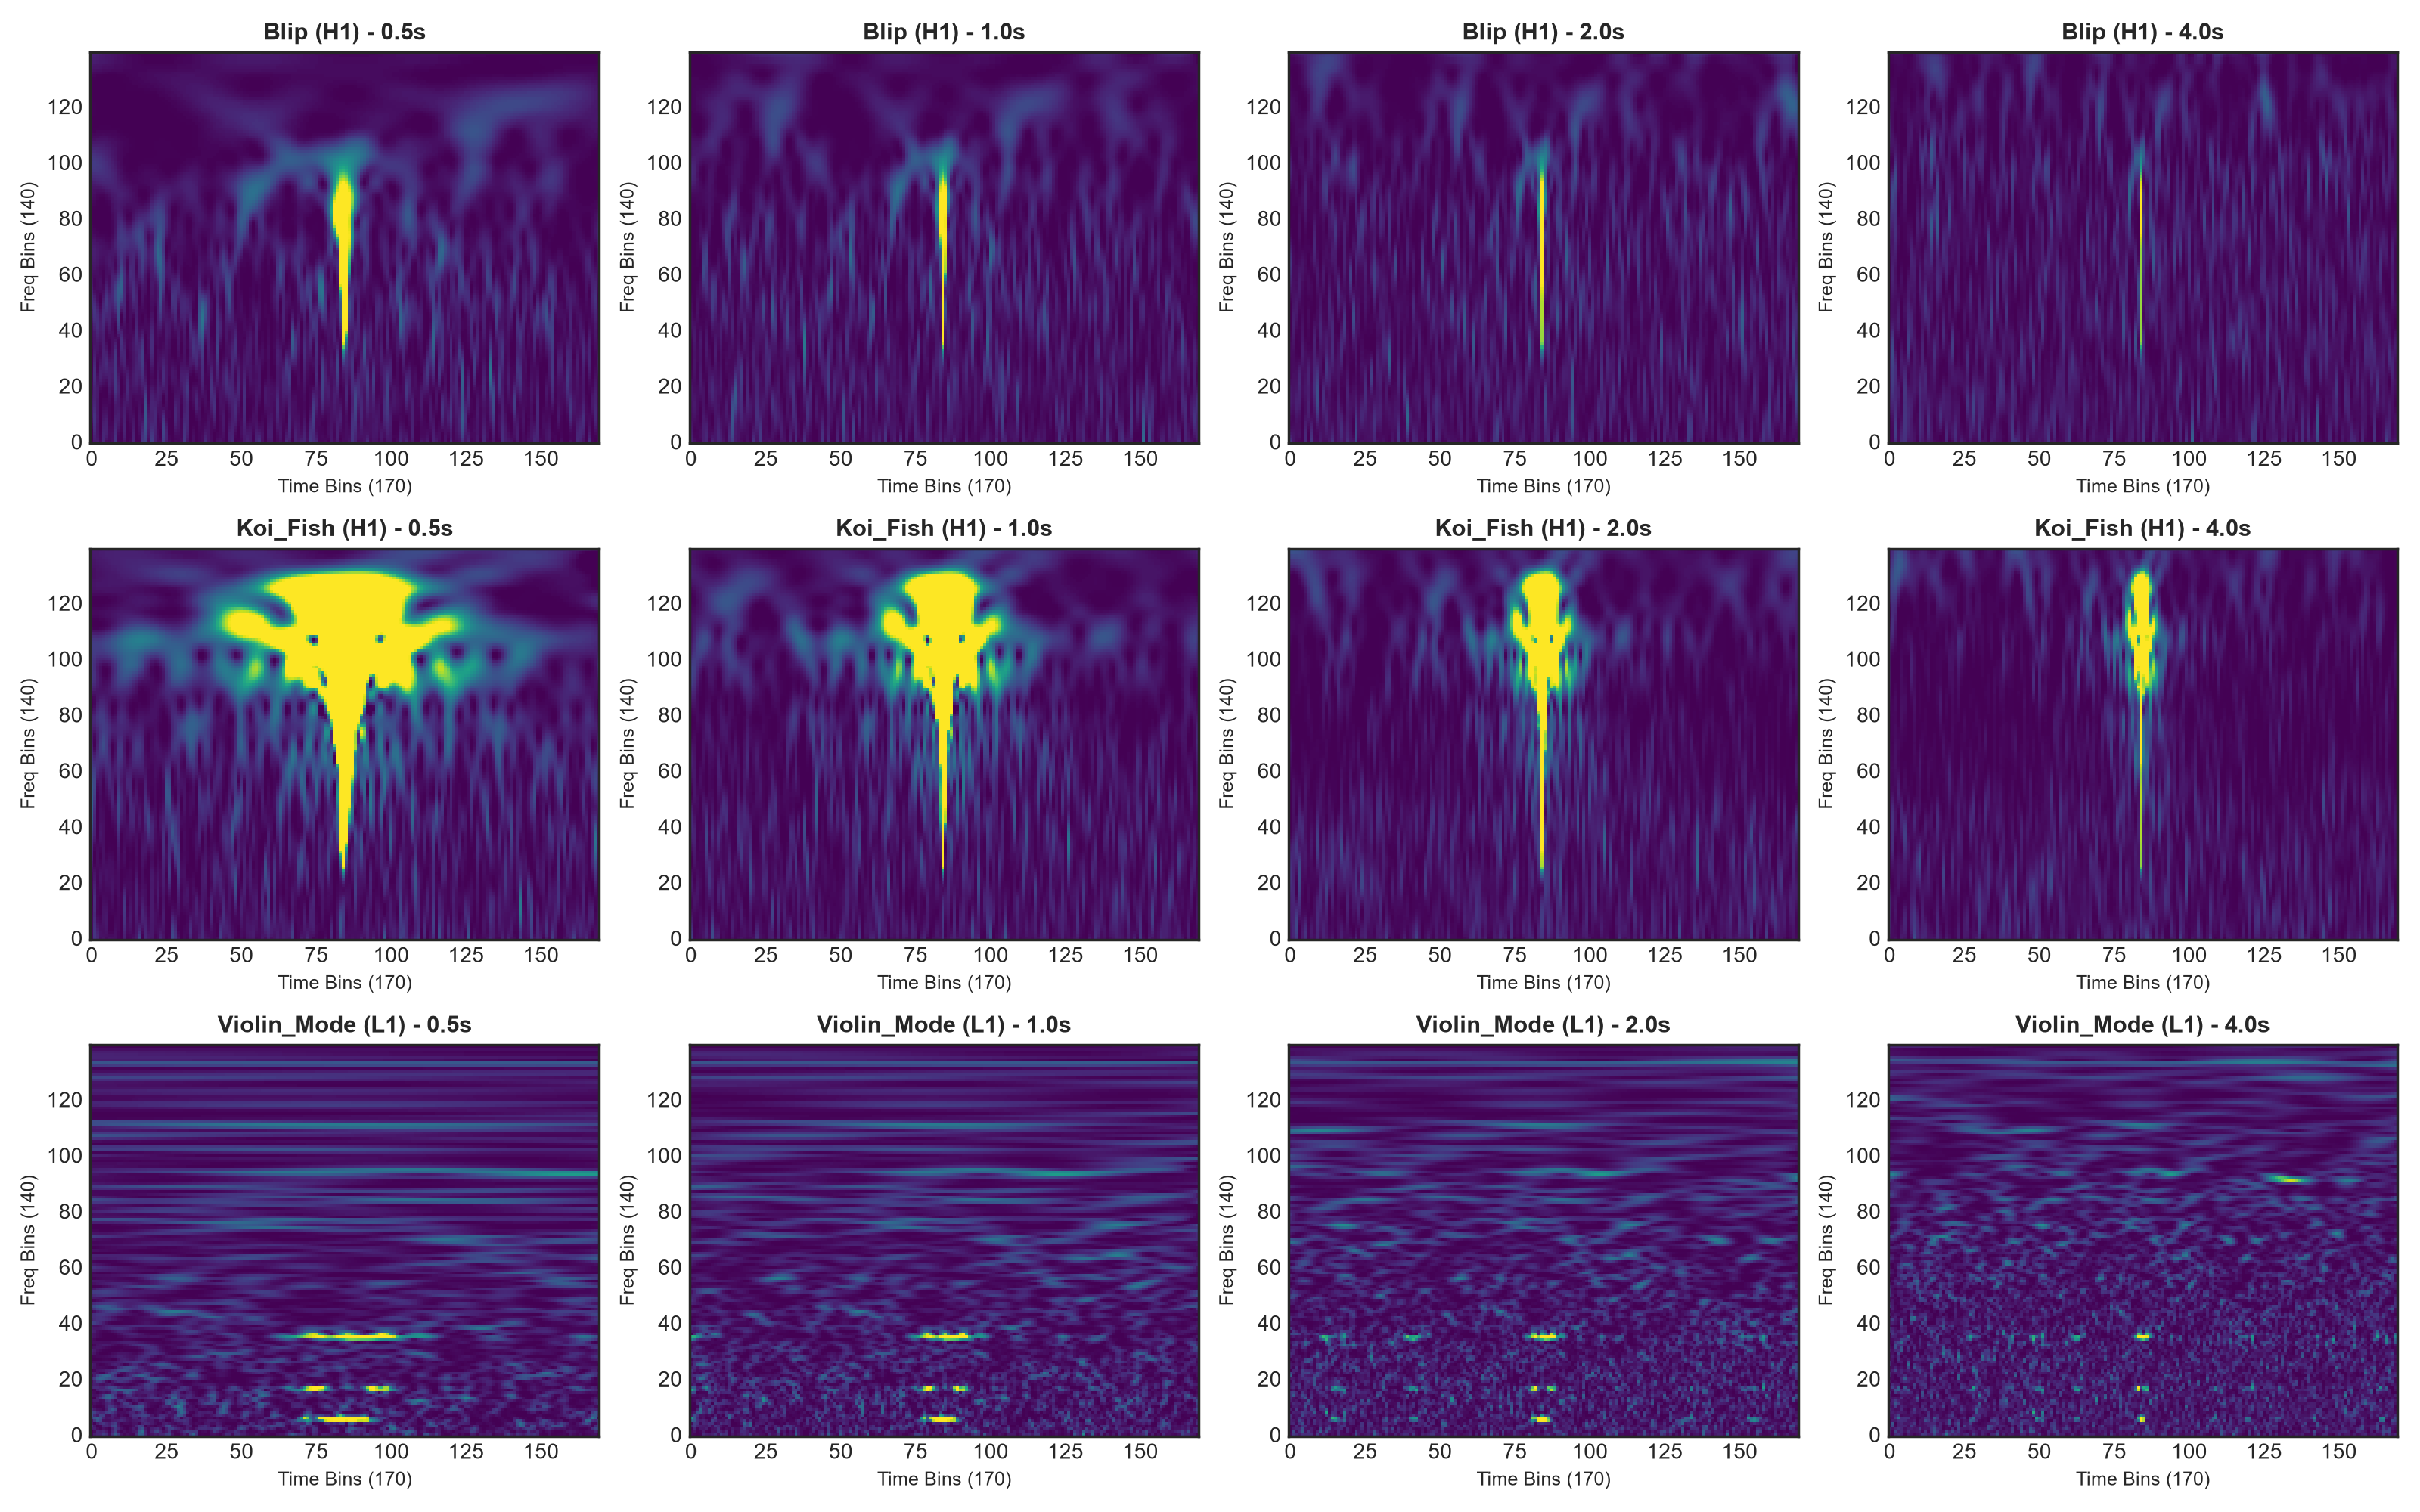

In [4]:
# Step 2.4: Visualize the 4 Duration Views Side-by-Side for Sample Glitch Classes

# Load our shared-classes metadata table
shared_meta_path = os.path.join('..', 'data', 'processed', 'shared_classes_metadata.csv')
meta_df = pd.read_csv(shared_meta_path)

# Select 3 distinct glitch classes with different morphological shapes
sample_classes = ['Blip', 'Koi_Fish', 'Violin_Mode']
durations = ['0.5s', '1.0s', '2.0s', '4.0s']

fig, axes = plt.subplots(nrows=len(sample_classes), ncols=4, figsize=(16, 10))

with h5py.File(h5_file_path, 'r') as h5_f:
    for row_idx, cls_name in enumerate(sample_classes):
        # Pick the first glitch belonging to this class
        sample_row = meta_df[meta_df['label'] == cls_name].iloc[0]
        gid = sample_row['gravityspy_id']
        stype = sample_row['sample_type']
        ifo = sample_row['ifo']
        
        # Load all 4 views
        views = load_all_views(h5_f, cls_name, stype, gid)
        
        for col_idx, dur in enumerate(durations):
            ax = axes[row_idx, col_idx]
            img = views[dur]
            
            # Display spectrogram with origin at bottom-left (low frequency at bottom)
            im = ax.imshow(img, cmap='viridis', origin='lower', aspect='auto')
            ax.set_title(f'{cls_name} ({ifo}) - {dur}', fontsize=11, fontweight='bold')
            ax.set_xlabel('Time Bins (170)', fontsize=9)
            ax.set_ylabel('Freq Bins (140)', fontsize=9)
            ax.grid(False)

plt.tight_layout()

# Save the visualization into outputs/figures/
fig_dir = os.path.join('..', 'outputs', 'figures')
os.makedirs(fig_dir, exist_ok=True)
save_fig_path = os.path.join(fig_dir, 'spectrogram_views_demo.png')
plt.savefig(save_fig_path, dpi=200)
print(f'Visualization saved to: {save_fig_path}')
plt.show()
plt.close(fig)

### Cell 4 Explanation: Multi-View Visual Inspection
- In the figure above, we plotted all 4 duration windows (0.5s, 1.0s, 2.0s, 4.0s) for three distinct glitch classes:
  1. **Blip:** An extremely short, teardrop-shaped burst. It is sharpest in the **0.5s** view and appears as a tiny thin line in the 4.0s view.
  2. **Koi Fish:** Has a characteristic teardrop body with prominent low-frequency "fins". Both 0.5s and 1.0s views clearly capture its shape.
  3. **Violin Mode:** Caused by thermal resonance of the mirror suspension fibers (~500 Hz). It forms a persistent horizontal line across time, which is most obvious in the **2.0s and 4.0s** views.
- **Key Takeaway:** Different glitch classes are best resolved at different temporal zooms. This confirms why multi-view representations provide rich complementary information.

In [5]:
# Step 2.5: Verify Which Measurements the Spectrogram Arrays Support
# In direct response to instructor's prompt: 'verify which measurements the spectrogram arrays support'

with h5py.File(h5_file_path, 'r') as h5_f:
    # Test on a Blip glitch
    test_img = load_spectrogram(h5_f, 'Blip', 'train', first_gid, view='1.0s')
    
    # Measurement 1: Peak Energy & Peak Coordinate Location
    peak_val = np.max(test_img)
    peak_freq_idx, peak_time_idx = np.unravel_index(np.argmax(test_img), test_img.shape)
    
    # Measurement 2: Energy by Frequency Sub-bands (Low, Mid, High)
    # Vertical axis has 140 bins: Low (<40), Mid (40-90), High (>90)
    low_band_energy = np.mean(test_img[:40, :])
    mid_band_energy = np.mean(test_img[40:90, :])
    high_band_energy = np.mean(test_img[90:, :])
    
    # Measurement 3: Active Duration (Time bins above noise threshold)
    # Threshold set at 75th percentile of pixel energy
    energy_thresh = np.percentile(test_img, 75)
    time_profile = np.max(test_img, axis=0) # maximum energy across time
    active_time_bins = np.sum(time_profile > energy_thresh)
    
    # Measurement 4: Spectral Centroid (Center of gravity along frequency axis)
    freq_weights = np.arange(140)
    freq_profile = np.mean(test_img, axis=1) # energy profile along frequency
    spectral_centroid_bin = np.sum(freq_weights * freq_profile) / (np.sum(freq_profile) + 1e-8)
    
    print('=== VERIFIED MEASUREMENTS SUPPORTED BY SPECTROGRAM ARRAY ===')
    print(f'1. Peak Energy Value          : {peak_val:.4f}')
    print(f'2. Peak Coordinate (Freq, Time): Bin ({peak_freq_idx}, {peak_time_idx})')
    print(f'3. Sub-band Energies (Low/Mid/Hi): {low_band_energy:.4f} / {mid_band_energy:.4f} / {high_band_energy:.4f}')
    print(f'4. Active Glitch Duration     : {active_time_bins} time bins (out of 170)')
    print(f'5. Spectral Centroid Bin      : {spectral_centroid_bin:.2f} (out of 140 bins)')

=== VERIFIED MEASUREMENTS SUPPORTED BY SPECTROGRAM ARRAY ===
1. Peak Energy Value          : 0.8694
2. Peak Coordinate (Freq, Time): Bin (49, 84)
3. Sub-band Energies (Low/Mid/Hi): 0.1269 / 0.1409 / 0.1490
4. Active Glitch Duration     : 165 time bins (out of 170)
5. Spectral Centroid Bin      : 71.87 (out of 140 bins)


### Cell 5 Explanation: Verification of Array-Supported Measurements
- In the cell above, we mathematically confirmed five precise features computable directly from the $140 \times 170$ array without external metadata:
  1. **Peak Location & Intensity:** The exact coordinate `(freq_bin, time_bin)` of maximum energy.
  2. **Frequency Sub-band Ratios:** Ratio of power concentrated in low frequencies vs. mid frequencies vs. high frequencies.
  3. **Active Glitch Duration:** Number of time slices where signal energy significantly exceeds background noise.
  4. **Spectral Centroid:** Center of mass of the frequency distribution.
- These will be formalized into our automated feature extractor in **Step 5**.

In [6]:
# Step 2.6: Test PyTorch LIGOGlitchDataset & DataLoader Integration

# Take a small 16-sample batch to test the pipeline
test_subset_df = meta_df.head(16).copy()

# Create single-view PyTorch dataset (1.0s view)
dataset_single = LIGOGlitchDataset(h5_file_path, test_subset_df, view='1.0s')
loader_single = DataLoader(dataset_single, batch_size=8, shuffle=False)

# Fetch the first batch from DataLoader
batch_imgs, batch_labels, batch_ids = next(iter(loader_single))

print('=== PYTORCH SINGLE-VIEW DATALOADER BATCH TEST ===')
print(f'Batch Image Tensor Shape: {batch_imgs.shape} (Expected: [batch_size, 1, 140, 170])')
print(f'Batch Labels Tensor Shape: {batch_labels.shape}')
print(f'Batch Labels (Integers) : {batch_labels.tolist()}')
print(f'Batch Sample Glitch IDs : {batch_ids[:3]}')

# Test 4-view multi-channel PyTorch dataset (view='all')
dataset_multi = LIGOGlitchDataset(h5_file_path, test_subset_df.head(4), view='all')
loader_multi = DataLoader(dataset_multi, batch_size=4, shuffle=False)
multi_imgs, _, _ = next(iter(loader_multi))
print(f'\nMulti-view Tensor Shape : {multi_imgs.shape} (Expected: [batch_size, 4, 140, 170])')

=== PYTORCH SINGLE-VIEW DATALOADER BATCH TEST ===
Batch Image Tensor Shape: torch.Size([8, 1, 140, 170]) (Expected: [batch_size, 1, 140, 170])
Batch Labels Tensor Shape: torch.Size([8])
Batch Labels (Integers) : [0, 1, 1, 0, 1, 1, 1, 1]
Batch Sample Glitch IDs : ('vSCZer8U3p', 'msSTHcULv9', 'mR2gNstPwo')

Multi-view Tensor Shape : torch.Size([4, 4, 140, 170]) (Expected: [batch_size, 4, 140, 170])


### Cell 6 Explanation: PyTorch DataLoader Readiness
- In the cell above, we verified that our custom `LIGOGlitchDataset` interacts seamlessly with PyTorch's native `DataLoader`.
- For single-view training, it emits tensors of shape `[batch_size, 1, 140, 170]`.
- For multi-view training, it stacks all 4 duration windows into a 4-channel tensor of shape `[batch_size, 4, 140, 170]`.
- Thread-safe file handles ensure that multi-process workers can read from the 3 GB HDF5 file without data corruption or deadlocks.